In [4]:
import pandas as pd

orders = pd.read_csv("data/olist_orders_dataset.csv")

print(orders.shape)
orders.head()


(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [6]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [7]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [8]:
orders.duplicated().sum()

np.int64(0)

In [9]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 13.0 MB


In [10]:
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M")
orders["purchase_month"].value_counts().sort_index().head(10)

purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
Freq: M, Name: count, dtype: int64

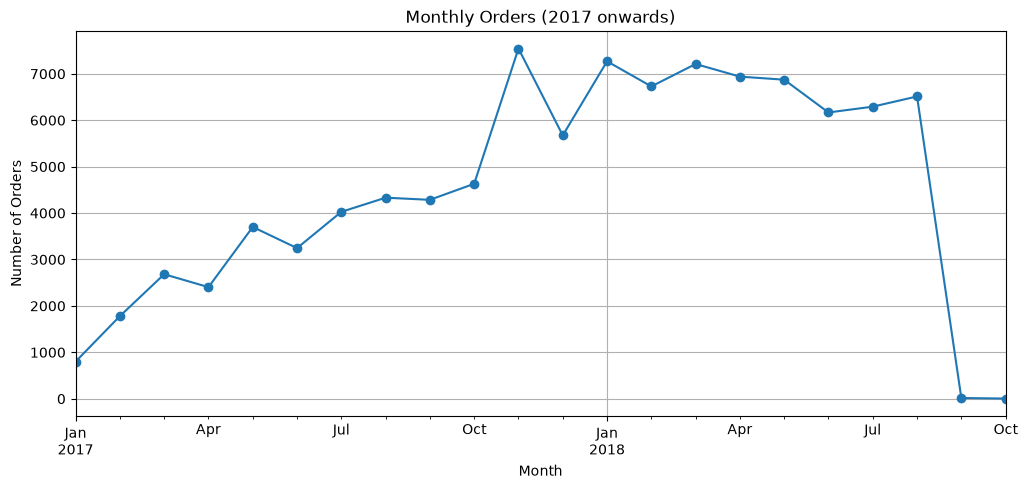

In [11]:
import matplotlib.pyplot as plt

monthly = orders["purchase_month"].value_counts().sort_index()
monthly = monthly[monthly.index >= "2017-01"]

monthly.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Orders (2017 onwards)")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.grid(True)
plt.show()

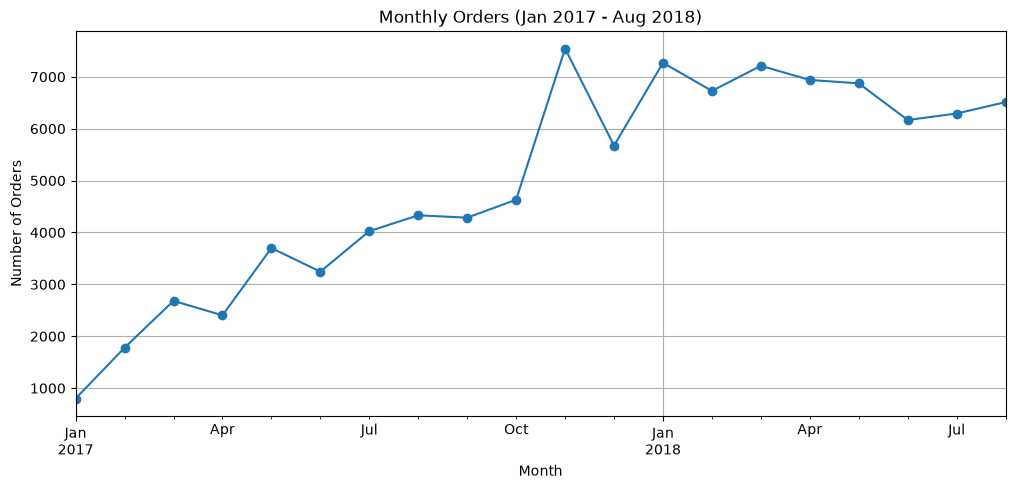

Peak month: 2017-11 with 7544 orders


In [12]:
monthly = orders["purchase_month"].value_counts().sort_index()
monthly = monthly[(monthly.index >= "2017-01") & (monthly.index <= "2018-08")]

monthly.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Orders (Jan 2017 - Aug 2018)")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.grid(True)
plt.show()

print("Peak month:", monthly.idxmax(), "with", monthly.max(), "orders")

In [13]:
items = pd.read_csv("data/olist_order_items_dataset.csv")
products = pd.read_csv("data/olist_products_dataset.csv")
translation = pd.read_csv("data/product_category_name_translation.csv")

print(items.shape, products.shape, translation.shape)
items.head(3)

(112650, 7) (32951, 9) (71, 2)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


In [14]:
df = items.merge(products, on="product_id", how="left")
df = df.merge(translation, on="product_category_name", how="left")

revenue = (
    df.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
revenue

product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64

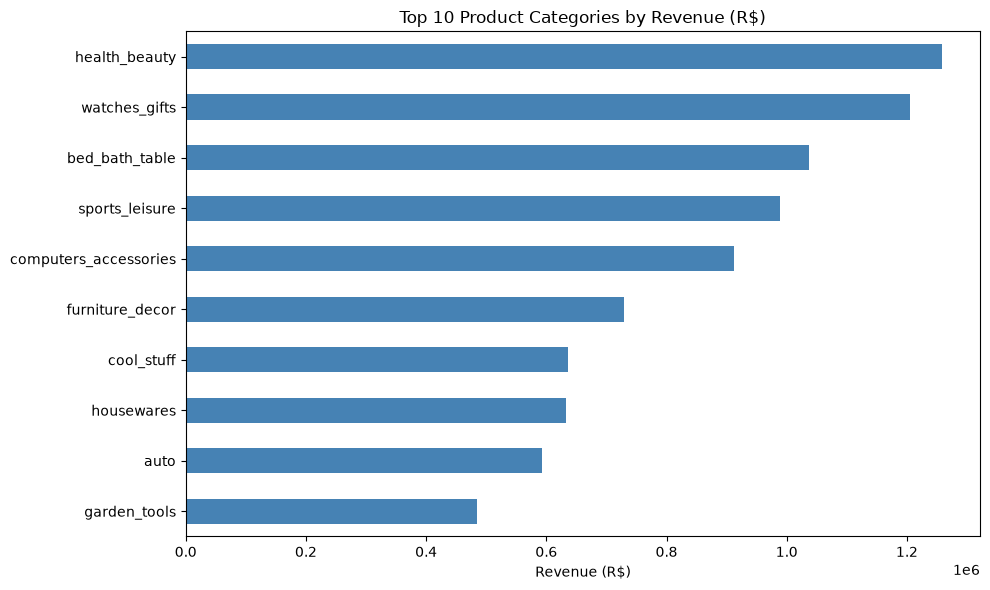

In [15]:
top10 = revenue.sort_values()

top10.plot(kind="barh", figsize=(10, 6), color="steelblue")
plt.title("Top 10 Product Categories by Revenue (R$)")
plt.xlabel("Revenue (R$)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [16]:
print("Items with no category:", df["product_category_name_english"].isnull().sum())

Items with no category: 1627


In [17]:
df["product_category_name_english"] = df["product_category_name_english"].fillna("unknown")
print(df["product_category_name_english"].value_counts().head(5))

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
Name: count, dtype: int64


In [18]:
volume = df["product_category_name_english"].value_counts().head(10)
volume

product_category_name_english
bed_bath_table           11115
health_beauty             9670
sports_leisure            8641
furniture_decor           8334
computers_accessories     7827
housewares                6964
watches_gifts             5991
telephony                 4545
garden_tools              4347
auto                      4235
Name: count, dtype: int64

In [19]:
customers = pd.read_csv("data/olist_customers_dataset.csv")

state_df = (
    orders.merge(customers, on="customer_id", how="left")
          .merge(items, on="order_id", how="left")
)

state_sales = (
    state_df.groupby("customer_state")
    .agg(orders=("order_id", "nunique"), revenue=("price", "sum"))
    .sort_values("revenue", ascending=False)
)

state_sales.head(10)

,orders,revenue
customer_state,,
SP,41746,5202955.05
RJ,12852,1824092.67
MG,11635,1585308.03
RS,5466,750304.02
PR,5045,683083.76
SC,3637,520553.34
BA,3380,511349.99
DF,2140,302603.94
GO,2020,294591.95


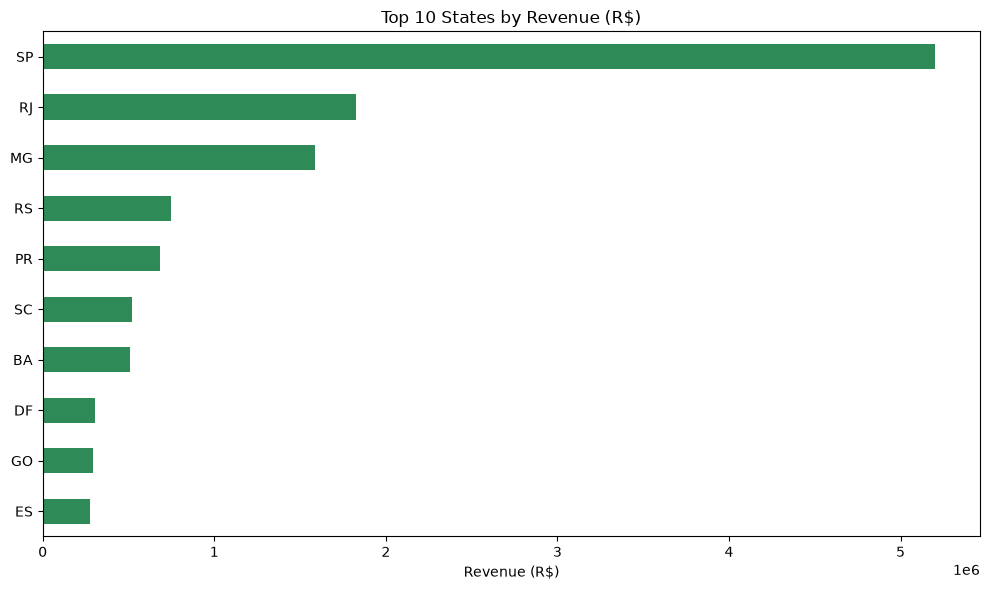

In [20]:
state_sales.head(10)["revenue"].sort_values().plot(
    kind="barh", figsize=(10, 6), color="seagreen"
)
plt.title("Top 10 States by Revenue (R$)")
plt.xlabel("Revenue (R$)")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [21]:
share = state_sales["revenue"].max() / state_sales["revenue"].sum()
print(f"SP share of total revenue: {share:.1%}")

SP share of total revenue: 38.3%


In [22]:
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")

delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["order_delivered_customer_date"])

delivered["days_late"] = (
    delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]
).dt.days
delivered["is_late"] = delivered["days_late"] > 0

review_df = delivered.merge(reviews[["order_id", "review_score"]], on="order_id", how="left")

print("Late orders:", round(review_df["is_late"].mean() * 100, 1), "%")
review_df.groupby("is_late")["review_score"].mean()

Late orders: 6.8 %


is_late
False    4.289980
True     2.271025
Name: review_score, dtype: float64

In [23]:
cust = orders.merge(customers, on="customer_id", how="left")
orders_per_customer = cust.groupby("customer_unique_id")["order_id"].nunique()

repeat_rate = (orders_per_customer > 1).mean()
print(f"Repeat customers: {repeat_rate:.1%}")
orders_per_customer.value_counts().head()

Repeat customers: 3.1%


order_id
1    93099
2     2745
3      203
4       30
5        8
Name: count, dtype: int64

In [24]:
master = (
    orders.merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
          .merge(items[["order_id", "product_id", "price", "freight_value"]], on="order_id", how="left")
          .merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
          .merge(translation, on="product_category_name", how="left")
          .merge(reviews.drop_duplicates("order_id")[["order_id", "review_score"]], on="order_id", how="left")
)

master["product_category_name_english"] = master["product_category_name_english"].fillna("unknown")
master["days_late"] = (master["order_delivered_customer_date"] - master["order_estimated_delivery_date"]).dt.days
master["is_late"] = master["days_late"] > 0
master["purchase_month"] = master["order_purchase_timestamp"].dt.to_period("M").astype(str)

master = master[(master["purchase_month"] >= "2017-01") & (master["purchase_month"] <= "2018-08")]
master.to_csv("data/master_orders.csv", index=False)
print(master.shape)

(113018, 19)


In [25]:
print("Unique orders:", master["order_id"].nunique())
print(master[master["purchase_month"] == "2017-11"]["order_id"].nunique())

Unique orders: 99092
7544


In [26]:
m = master[master["order_status"] == "delivered"]
print(m.groupby("is_late")["review_score"].mean())
print(m.drop_duplicates("order_id").groupby("is_late")["review_score"].mean())

is_late
False    4.209778
True     2.257559
Name: review_score, dtype: float64
is_late
False    4.291513
True     2.271715
Name: review_score, dtype: float64
